<a href="https://colab.research.google.com/github/greeshmareddy98/MLA0201-FOML/blob/main/EXP_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

df = pd.read_csv('/experiment10_em_100.csv')

print(df.head())
print("Total rows:", len(df))
print("Columns:", df.columns.tolist())

   Feature1  Feature2
0     1.637     1.032
1     1.838     1.923
2     0.622     0.914
3     1.558     1.358
4     1.492     1.116
Total rows: 100
Columns: ['Feature1', 'Feature2']


In [2]:
from sklearn.mixture import GaussianMixture

# Select features
X = df[['Feature1', 'Feature2']]

# Apply EM algorithm
em = GaussianMixture(n_components=3, random_state=42)
em.fit(X)

# Predict clusters
df['Cluster'] = em.predict(X)

print("Cluster counts:")
print(df['Cluster'].value_counts().sort_index())

print("\nCluster means:")
print(em.means_)

Cluster counts:
Cluster
0    33
1    33
2    34
Name: count, dtype: int64

Cluster means:
[[4.94351515 4.87987879]
 [8.49045455 1.53424242]
 [1.53367647 1.51055882]]


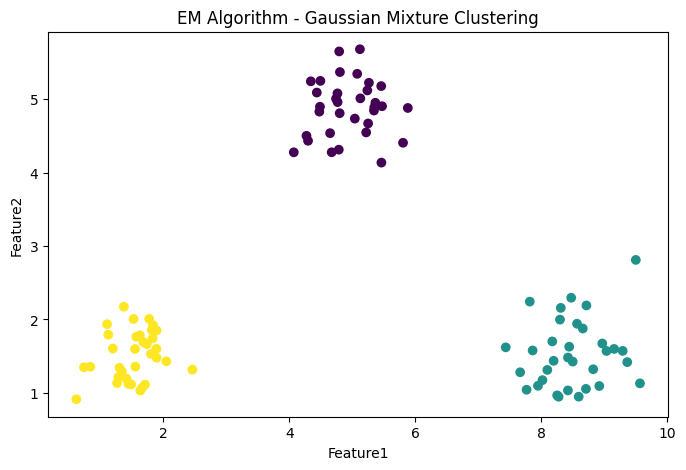

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    df['Feature1'],
    df['Feature2'],
    c=df['Cluster'],
    cmap='viridis'
)

plt.xlabel('Feature1')
plt.ylabel('Feature2')
plt.title('EM Algorithm - Gaussian Mixture Clustering')
plt.savefig('experiment10_em_graph.png')
plt.show()